# LDA Deck-Level Model
**Modeling — Deck Granularity**

Implements LDA at slide-deck level following the CRISP-DM modeling phase.  
Library: `tomotopy` (Collapsed Gibbs Sampling).  
Input: deck-level token lists produced by `src/utils.py`.  
Granularity: one document = one full slide deck (all pages of one lecture PDF aggregated).  
Corpus size: 9 documents (one per IDS lecture PDF).

> **Statistical constraint.** With 9 documents LDA operates below its typical minimum corpus
> requirements. Document-topic distributions carry high uncertainty; results should be
> interpreted as exploratory curriculum-level thematic profiles, not statistically stable
> topic models. See Section 6 for a full discussion.

**Structure:**
1. Setup & Data Loading
2. Corpus Preparation
3. Model Training
4. Topic Inspection
5. Evaluation (Coherence & Perplexity)
6. Model Summary & Review

## 1. Setup & Data Loading

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

_nb_dir = os.path.dirname(os.path.abspath('lda.ipynb'))
_src_dir = os.path.abspath(os.path.join(_nb_dir, '..'))
if _src_dir not in sys.path:
    sys.path.insert(0, _src_dir)

warnings.filterwarnings('ignore')

# Plotting defaults
plt.rcParams.update({
    'figure.dpi'       : 130,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.titlesize'   : 13,
    'axes.labelsize'   : 11,
    'font.family'      : 'serif',
})
PALETTE = ['#2C5F8A', '#4C9BE8', '#A8C8E8', '#D9E8F5']

print('Libraries loaded.')

Libraries loaded.


In [2]:
from utils import load_corpus, tokenize_corpus, build_slide_deck_docs

# Load and Tokenize corpus
corpus = tokenize_corpus(load_corpus())

# Aggregate to deck level. One document per slide PDF.
docs = build_slide_deck_docs(corpus)

print(f'Documents (decks): {len(docs)}')
print(f'Token count — min: {docs.n_tokens.min()}, median: {docs.n_tokens.median():.0f}, max: {docs.n_tokens.max()}')
docs[['source_file', 'n_tokens']]

Documents (decks): 9
Token count — min: 58, median: 410, max: 669


,source_file,n_tokens
0,icd_1_v1_cleaned_v7.csv,488
1,icd_2_v1_cleaned_v7.csv,568
2,icd_3_v1_cleaned_v7.csv,669
3,icd_4_v1_cleaned_v7.csv,230
4,icd_5_v1_cleaned_v7.csv,58
5,icd_6_v1_cleaned_v7.csv,410
6,icd_7_v1_cleaned_v7.csv,523
7,icd_8_v1_cleaned_v7.csv,130
8,icd_9_v1_cleaned_v7.csv,270


## 2. Corpus Preparation

In [3]:
import tomotopy as tp
from tomotopy.coherence import Coherence

RANDOM_SEED = 42

texts = docs['tokens'].tolist()

# Conservative vocabulary filter: min_df=2 (same effective vocab as lda_v3)
print(f'Corpus size: {len(texts)} documents')
# Conservative vocabulary filter: min_df=2 (same effective vocab as lda_v3)
print(f'tomotopy version: {tp.__version__}')

Corpus size: 9 documents
tomotopy version: 0.14.0


## 3. Model Training

In [4]:
# k=5: must stay below n_docs (9); 5 allows meaningful separation without overfitting
NUM_TOPICS  = 5
ITERATIONS  = 2000  # more iterations to compensate for small corpus
ALPHA       = 0.1
ETA         = 0.01

lda = tp.LDAModel(
    k      = NUM_TOPICS,
    alpha  = ALPHA,
    eta    = ETA,
    min_df = 2,
    rm_top = 0,
    seed   = RANDOM_SEED,
)

for token_list in texts:
    lda.add_doc(token_list)

lda.train(0)
lda.train(ITERATIONS, workers=1)

print(f'LDA trained: {lda.k} topics, {ITERATIONS} iterations, seed={RANDOM_SEED}')
print(f'Vocabulary: {lda.num_vocabs} terms')

LDA trained: 5 topics, 2000 iterations, seed=42
Vocabulary: 338 terms


## 4. Topic Inspection

In [5]:
# Top terms per topic

TOP_N = 10
for i in range(NUM_TOPICS):
    terms    = lda.get_topic_words(i, top_n=TOP_N)
    term_str = ' + '.join(f'{p:.3f}*"{w}"' for w, p in terms)
    print(f'Topic {i:02d}: {term_str}')

Topic 00: 0.073*"informação" + 0.042*"imagem" + 0.035*"texto" + 0.031*"tratamento" + 0.024*"conteúdo" + 0.024*"fonte" + 0.021*"volume" + 0.021*"utilização" + 0.021*"aplicação" + 0.019*"mining"
Topic 01: 0.059*"ciência" + 0.059*"processo" + 0.046*"análise" + 0.044*"visualização" + 0.039*"conhecimento" + 0.039*"numérico" + 0.035*"contexto" + 0.033*"aluno" + 0.026*"introdução" + 0.024*"projeto"
Topic 02: 0.146*"variável" + 0.101*"valores" + 0.073*"atributo" + 0.063*"categórico" + 0.057*"classificação" + 0.054*"regressão" + 0.038*"identificação" + 0.035*"target" + 0.025*"dataset" + 0.025*"transformação"
Topic 03: 0.089*"objetivo" + 0.065*"aprendizagem" + 0.034*"recap" + 0.031*"estudante" + 0.031*"distância" + 0.031*"clustering" + 0.031*"algoritmo" + 0.028*"tarefa" + 0.028*"média" + 0.028*"desempenho"
Topic 04: 0.139*"modelo" + 0.060*"resultado" + 0.043*"avaliação" + 0.041*"conjunto" + 0.034*"previsão" + 0.031*"base" + 0.029*"decisão" + 0.029*"features" + 0.026*"problema" + 0.024*"treino"


In [6]:
from utils import generate_topic_labels

TOPIC_LABELS = generate_topic_labels(lda, NUM_TOPICS, topn=3)

for idx, label in TOPIC_LABELS.items():
    print(f'T{idx:02d}: {label}')

T00: Informação · Imagem · Texto
T01: Ciência · Processo · Análise
T02: Variável · Valores · Atributo
T03: Objetivo · Aprendizagem · Recap
T04: Modelo · Resultado · Avaliação


In [15]:
# Topic summary table

rows = []
for i in range(NUM_TOPICS):
    terms = lda.get_topic_words(i, top_n=TOP_N)
    top_words   = ', '.join(w for w, _ in terms)
    top_weights = [round(p, 3) for _, p in terms]
    rows.append({
        'Topic'       : f'T{i:02d}',
        'Label'       : TOPIC_LABELS[i],
        'Top 10 Terms': top_words,
        'Max weight'  : max(top_weights),
    })

topic_df = pd.DataFrame(rows).set_index('Topic')

topic_df.style \
    .set_caption('LDA Topics — Top 10 Terms per Topic (tomotopy, deck-level)') \
    .set_properties(**{'text-align': 'left'}) \
    .bar(subset=['Max weight'], color='#0156AB', vmin=0, vmax=0.15)

,Label,Top 10 Terms,Max weight
Topic,,,
T00,Informação · Imagem · Texto,"informação, imagem, texto, tratamento, conteúdo, fonte, volume, utilização, aplicação, mining",0.073000
T01,Ciência · Processo · Análise,"ciência, processo, análise, visualização, conhecimento, numérico, contexto, aluno, introdução, projeto",0.059000
T02,Variável · Valores · Atributo,"variável, valores, atributo, categórico, classificação, regressão, identificação, target, dataset, transformação",0.146000
T03,Objetivo · Aprendizagem · Recap,"objetivo, aprendizagem, recap, estudante, distância, clustering, algoritmo, tarefa, média, desempenho",0.089000
T04,Modelo · Resultado · Avaliação,"modelo, resultado, avaliação, conjunto, previsão, base, decisão, features, problema, treino",0.139000


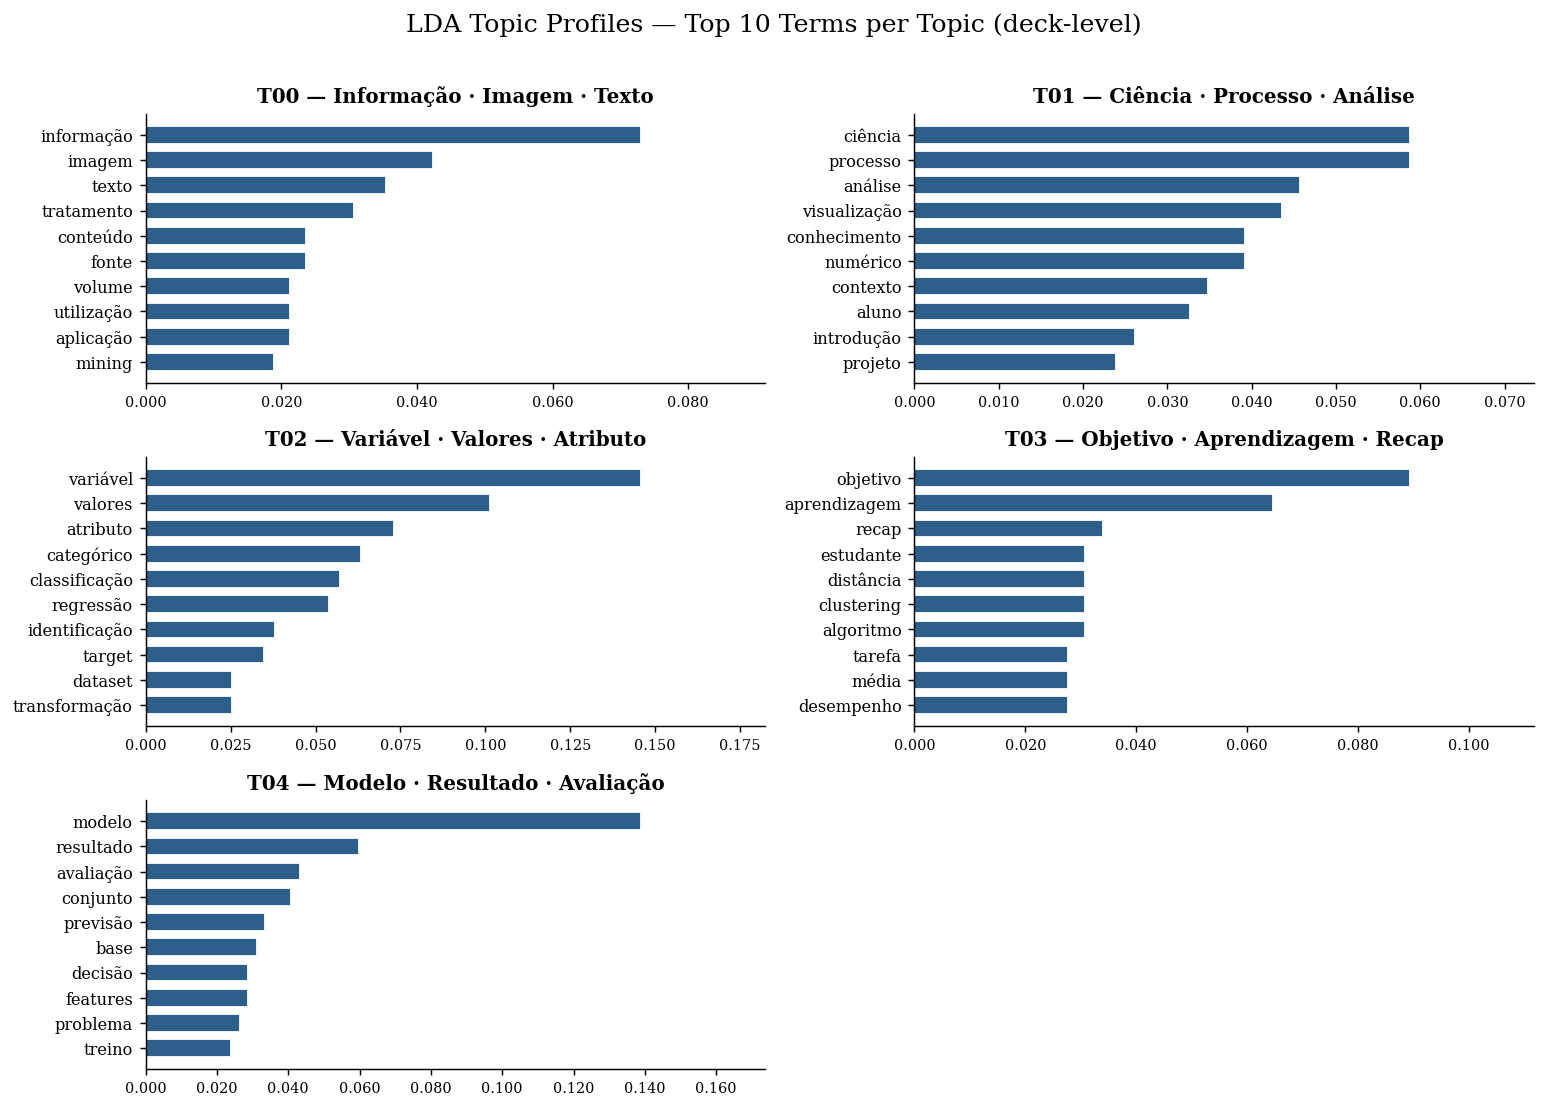

In [8]:
# Visualize topic profiles

TOP_VIS = 10
n_cols = 2
n_rows = (NUM_TOPICS + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, n_rows * 2.8))
axes = axes.flatten()

for i in range(NUM_TOPICS):
    terms   = lda.get_topic_words(i, top_n=TOP_VIS)
    words   = [w for w, _ in terms][::-1]
    weights = [p for _, p in terms][::-1]

    ax = axes[i]
    ax.barh(words, weights, color=PALETTE[0], edgecolor='white', height=0.7)
    ax.set_title(f'T{i:02d} — {TOPIC_LABELS[i]}', fontsize=11, fontweight='bold')
    ax.set_xlim(0, max(weights) * 1.25)
    ax.tick_params(axis='y', labelsize=9)
    ax.tick_params(axis='x', labelsize=8)
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))

for j in range(NUM_TOPICS, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('LDA Topic Profiles — Top 10 Terms per Topic (deck-level)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

               source_file  n_tokens  dominant_topic
0  icd_1_v1_cleaned_v7.csv       488               1
1  icd_2_v1_cleaned_v7.csv       568               0
2  icd_3_v1_cleaned_v7.csv       669               4
3  icd_4_v1_cleaned_v7.csv       230               1
4  icd_5_v1_cleaned_v7.csv        58               1
5  icd_6_v1_cleaned_v7.csv       410               2
6  icd_7_v1_cleaned_v7.csv       523               4
7  icd_8_v1_cleaned_v7.csv       130               3
8  icd_9_v1_cleaned_v7.csv       270               0


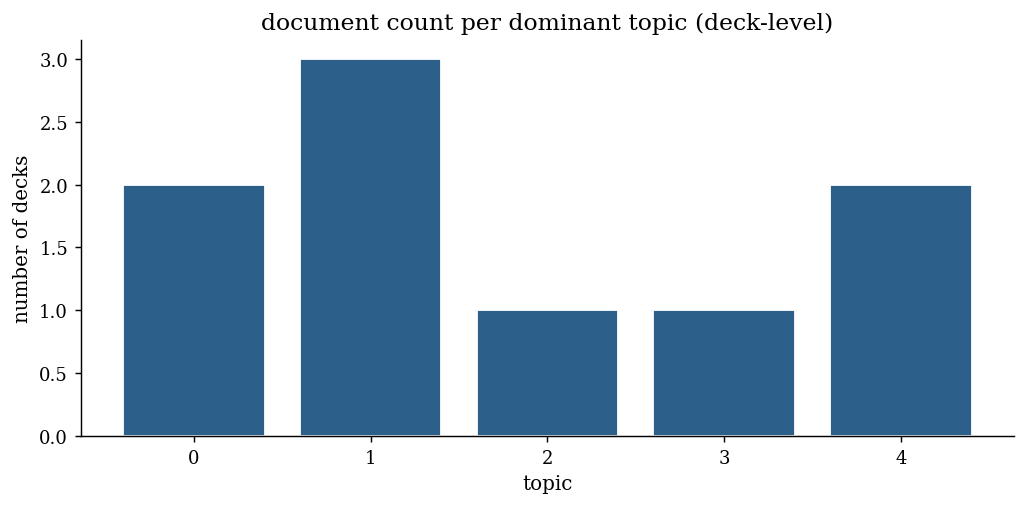

In [9]:
# Visualize document-topic distribution

docs = docs.copy()
docs['dominant_topic'] = [
    int(np.argmax(doc.get_topic_dist())) for doc in lda.docs
]

print(docs[['source_file', 'n_tokens', 'dominant_topic']].to_string())

topic_dist = docs['dominant_topic'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(topic_dist.index, topic_dist.values, color=PALETTE[0], edgecolor='white')
ax.set_xlabel('topic')
ax.set_ylabel('number of decks')
ax.set_title('document count per dominant topic (deck-level)')
ax.set_xticks(range(NUM_TOPICS))
plt.tight_layout()
plt.show()

## 5. Evaluation

In [10]:
# Coherence score (C_v) for the current model

coh = Coherence(lda, coherence='c_v')
coherence_cv = coh.get_score()
perplexity   = lda.perplexity

print(f'Coherence (C_v) : {coherence_cv:.4f}  (target > 0.50)')
print(f'Perplexity      : {perplexity:.4f}')

Coherence (C_v) : 0.5894  (target > 0.50)
Perplexity      : 416.5865


k= 2  C_v=0.5305
k= 3  C_v=0.6157
k= 4  C_v=0.6292
k= 5  C_v=0.5894
k= 6  C_v=0.6112
k= 7  C_v=0.6042
k= 8  C_v=0.6235


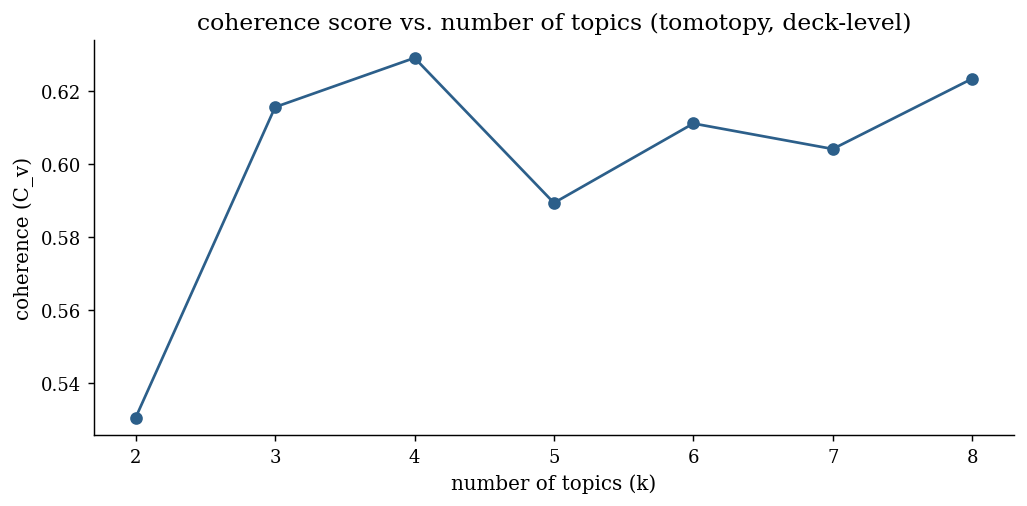


Best k=4  C_v=0.6292


In [11]:
# Coherence grid search over number of topics
# Helps to find the optimal K before committing to a final model and parameters.

TOPIC_RANGE = range(2, 9)

results = []
for k in TOPIC_RANGE:
    m = tp.LDAModel(k=k, alpha=ALPHA, eta=ETA, min_df=2, rm_top=0, seed=RANDOM_SEED)
    for token_list in texts:
        m.add_doc(token_list)
    m.train(0)
    m.train(ITERATIONS, workers=1)
    cv = Coherence(m, coherence='c_v').get_score()
    results.append({'k': k, 'coherence_cv': round(cv, 4)})
    print(f'k={k:2d}  C_v={cv:.4f}')

results_df = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(results_df['k'], results_df['coherence_cv'], marker='o', color=PALETTE[0])
ax.set_xlabel('number of topics (k)')
ax.set_ylabel('coherence (C_v)')
ax.set_title('coherence score vs. number of topics (tomotopy, deck-level)')
ax.set_xticks(list(TOPIC_RANGE))
plt.tight_layout()
plt.show()

best = results_df.loc[results_df['coherence_cv'].idxmax()]
print(f'\nBest k={int(best.k)}  C_v={best.coherence_cv}')